## Fuente de datos

https://zenodo.org/records/2560316

The Spanish Clinical Case Corpus (SPACCC) corpus corresponds to a manually classified collection of clinical case reports (specifically clinical case description sections) derived from open access Spanish medical publications (SciELO). The SPACCC corpus contained a total of 101 clinical cases. It is noteworthy that this kind of narrative shows properties of both the biomedical and medical literature, as well as clinical records (e.g. discharge summaries).

## EDA 

In [1]:


import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 160)

In [8]:
df_evaluate=pd.read_excel("C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Audit HC (2).xlsx")

## Nota Texto
Describir que se modifico la donde se agregaron las columnas "" Num_Words" y variables como stop words_Ratio. 

Se solicito a un experto evaluar 101 notas donde se explicada el motivo de consulta, enfermedad actual, examen fisico, diagnóstico 

In [9]:
df_evaluate

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años que acude a consulta por dolor en la muñeca derecha de 7 años de evolución sin antecedente traumático. El dol...,432,0.432558,1.0,1.0,1.0,1.0
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. El estudio radiográfico reveló una gran lesión radiolúcida y una fractura del ángulo desplazada.\n\nSe realizó...,69,0.362319,1.0,0.0,0.0,1.0
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés que consultó por diarrea y síndrome general de un año de evolución. En la exploración física destacaba una masa...,148,0.412162,1.0,1.0,1.0,1.0
3,S0212-16112008000500014-1,"Varón de 78 años que ingresa en Medicina Interna del hospital, procedente de las consultas externas, refiriendo aumento en el número y volumen de las deposi...",587,0.492877,1.0,1.0,1.0,0.0
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemocromatosis estadio B8 de Child con múltiples ingresos con el diagnóstico de encefalopatía hepática severa recu...,224,0.384615,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años con antecedentes de hipertensión arterial y cardiopatía isquémica que se encontraba en estudio por un cuadro d...,251,0.483607,NaN,NaN,NaN,NaN
993,S0210-48062009000300013-3,"Varón de 74 años\nAntecedentes personales: HTA esencial previa (En tratamiento con Enalapril), Hipercolesterolemia.\nLitiasis cálcica de 1 cm en infundíbulo...",146,0.355072,NaN,NaN,NaN,NaN
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las consultas externas del servicio de digestivo para valorar unas lesiones que han aparecido recientemente en la ...,269,0.470149,NaN,NaN,NaN,NaN
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés que ingresó por dolor en epigastrio-hipocondrio derecho irradiado a la escápula junto con ictericia e intoleran...,281,0.418251,NaN,NaN,NaN,NaN


In [10]:
df_f = df_evaluate.dropna(subset=['Motivo de consulta', 'Enfermedad actual', 'Examen Físico', 'Diagnóstico'])


In [11]:
len(df_f)

98

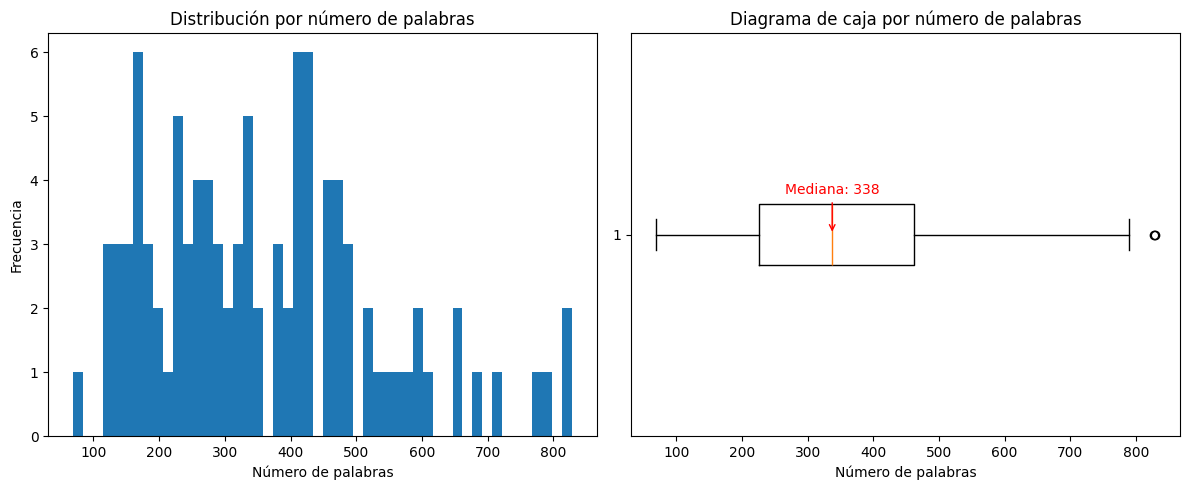

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(df_f["num_words"], bins=50)
ax1.set_title("Distribución por número de palabras")
ax1.set_xlabel("Número de palabras")
ax1.set_ylabel("Frecuencia")

mediana = df_f["num_words"].median()

ax2.boxplot(df_f["num_words"], vert=False)
ax2.set_title("Diagrama de caja por número de palabras")
ax2.set_xlabel("Número de palabras")
ax2.annotate(f"Mediana: {mediana:.0f}",
             xy=(mediana, 1), xytext=(mediana, 1.1),
             ha="center", color="red",
             arrowprops=dict(arrowstyle="->", color="red"))

plt.tight_layout()
plt.show()

Vale la pena dividir la base en el numero de palabras para saber si esta muy desbalanceado con un diagrama de pastel para saber si esta desvalanceado en cada criterio
Tambien vale la pena dividir los criterios para sber que clase es mas enriquecida en texto

Distribución del texto por clases


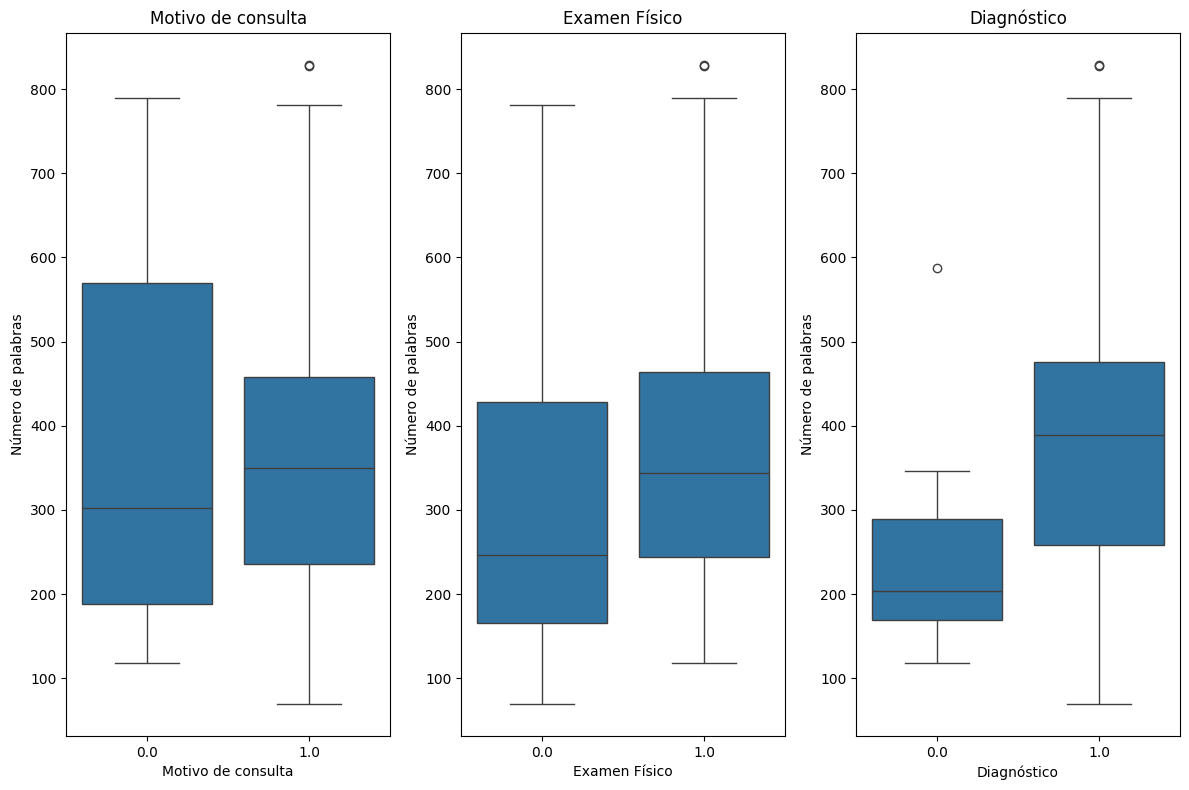

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

criterios = ['Motivo de consulta', 'Examen Físico', 'Diagnóstico']

fig, axes = plt.subplots(1, 3, figsize=(12, 8))

for ax, c in zip(axes.flat, criterios):
    sns.boxplot(data=df_f, x=c, y="num_words", ax=ax)
    ax.set_title(c)
    ax.set_xlabel(c)
    ax.set_ylabel("Número de palabras")

plt.tight_layout()
plt.show()

Tres criterios presentan un desbalance moderado (~80/20) y `Enfermedad actual`
uno severo (~94/6). Esto implica que la exactitud (accuracy) no es una métrica
confiable para evaluar los modelos futuros: se debe reportar
precision, recall y F1 por clase. Además, obliga a usar validación estratificada
y sugiere aplicar `class_weight='balanced'` al entrenar. `Enfermedad actual`
requiere cautela especial: con solo 6 casos en la clase minoritaria, cualquier
métrica sobre esa clase será inestable.

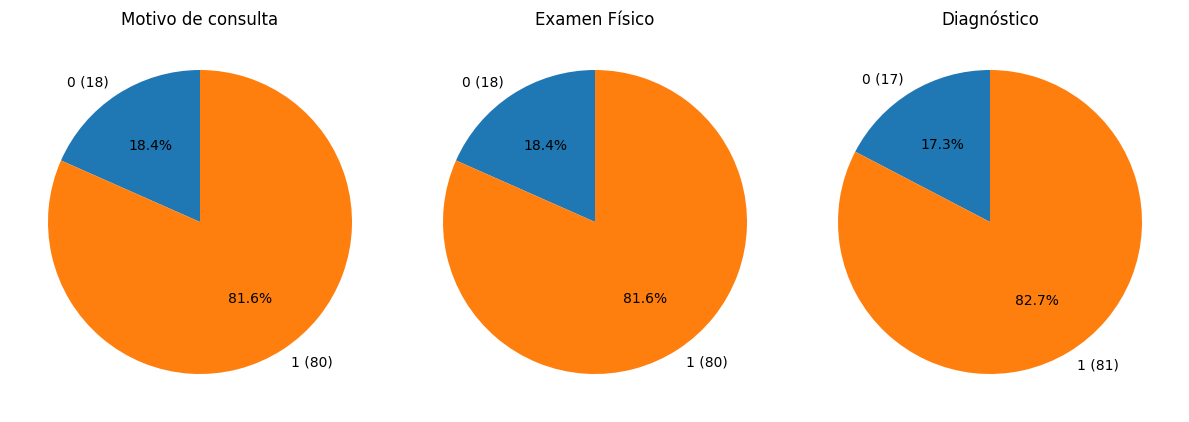

In [15]:
import matplotlib.pyplot as plt

criterios = ['Motivo de consulta', 'Examen Físico', 'Diagnóstico']

fig, axes = plt.subplots(1, 3, figsize=(12, 8))

for ax, c in zip(axes.flat, criterios):
    conteo = df_f[c].value_counts().sort_index()  # index 0 y 1
    ax.pie(conteo,
           labels=[f"0 ({conteo.get(0, 0)})", f"1 ({conteo.get(1, 0)})"],
           autopct="%1.1f%%",
           startangle=90)
    ax.set_title(c)

plt.tight_layout()
plt.show()

Esta grafica me muestra como las clases estan un poco desbalanceadas por lo que vale la pena verificar esto y mejorar el texto




### Limpieza y procesamiento de información

In [17]:
stop_words = pd.read_excel("C:\\Users\\raultc\\Documents\\MAA\\PROYECTO\\proyecto final\\stop words spanish.xlsx")

In [18]:
# Convertir a lista — asumiendo que las palabras están en la primera columna
SPANISH_STOP_WORDS = set(stop_words.iloc[:, 0].str.lower().tolist())

# Crear el vectorizer
vectorizer = CountVectorizer(stop_words=list(SPANISH_STOP_WORDS))

In [19]:
# Cargar y limpiar
SPANISH_STOP_WORDS = set(
    stop_words.iloc[:, 0]
    .dropna()                    # eliminar celdas vacías
    .str.strip()                 # eliminar espacios
    .str.lower()                 # convertir a minúsculas
    .tolist()
)

EXTRA_STOPS = {
    "que", "o", "si",
    # números escritos
    "uno", "dos", "tres", "cuatro", "cinco", "seis", "siete", "ocho", "nueve", "diez", "años", "meses", "días", "semanas", "horas", "minutos", "segundos", "día"
    # unidades médicas
    "mg", "dl", "ml", "cm", "mm", "kg", "gr", "g", "l", "ui", "meq",
    "mmhg", "lpm", "rpm", "mcg", "ng", "pg", "um", "nm", "iu", "cc","mg"
}

SPANISH_STOP_WORDS = SPANISH_STOP_WORDS | EXTRA_STOPS


In [20]:
import re
from collections import Counter

def simple_tokenize(text):
    tokens = re.findall(r"\b[a-záéíóúüñ]+\b", text.lower())
    return tokens


def get_top_words(texts, n=20, remove_stopwords=False):

    all_words = []

    for text in texts:
        tokens = simple_tokenize(text)

        # Remover stop words si se solicita
        if remove_stopwords:
            tokens = [word for word in tokens
                      if word not in SPANISH_STOP_WORDS]

        all_words.extend(tokens)

    # Contar frecuencias
    word_counts = Counter(all_words)

    # Retornar top n
    return word_counts.most_common(n)

def plot_top_words(top_words, title):
    """
    Grafica una lista de tuplas: [(palabra, frecuencia), ...]
    """
    words = [w for w, c in top_words]
    counts = [c for w, c in top_words]

    plt.figure(figsize=(10, 5))
    plt.bar(words, counts)
    plt.title(title)
    plt.xlabel("Palabra")
    plt.ylabel("Frecuencia")
    plt.xticks(rotation=45, ha="right")
    plt.show()

In [21]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)        # eliminar HTML
    text = re.sub(r"http\S+|www\S+", " ", text)  # eliminar URLs
    text = re.sub(r"[^a-z\s]", " ", text)        # eliminar no alfabéticos
    tokens = text.split()
    tokens = [w for w in tokens if w not in SPANISH_STOP_WORDS]
    return " ".join(tokens)


# Aplicar al dataset
df_f["nota_clean"] = df_f["nota"].apply(clean_text)

Promedio palabras original: 361.48
Promedio palabras sin stopwords: 196.29


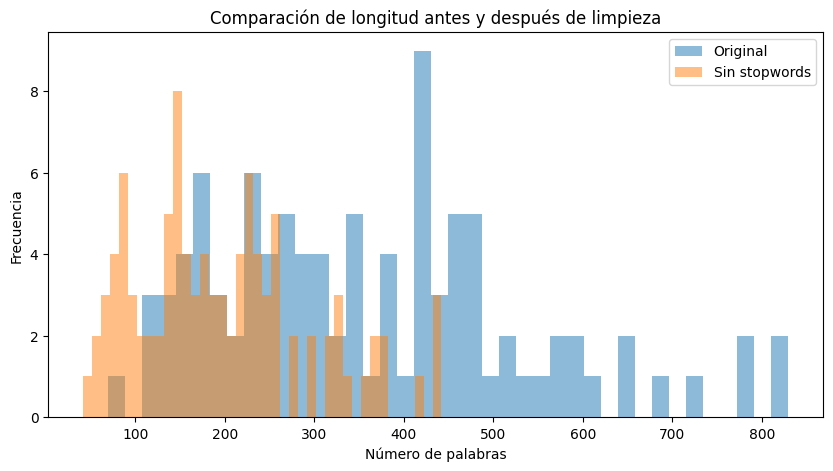

In [22]:
df_f["num_words_clean"] = df_f["nota"].apply(
    lambda x: len([w for w in simple_tokenize(x) if w not in SPANISH_STOP_WORDS])
)

print("Promedio palabras original:", round(df_f["num_words"].mean(), 2))
print("Promedio palabras sin stopwords:", round(df_f["num_words_clean"].mean(), 2))

plt.figure(figsize=(10, 5))
plt.hist(df_f["num_words"], bins=40, alpha=0.5, label="Original")
plt.hist(df_f["num_words_clean"], bins=40, alpha=0.5, label="Sin stopwords")
plt.title("Comparación de longitud antes y después de limpieza")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

In [24]:
top_all_raw = get_top_words(df_f["nota"], n=20, remove_stopwords=False)
top_all_clean = get_top_words(df_f["nota"], n=10, remove_stopwords=True)

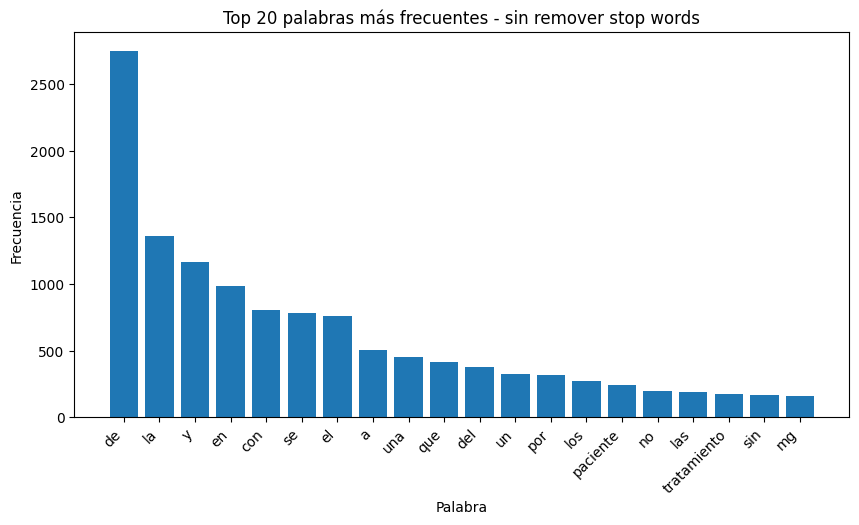

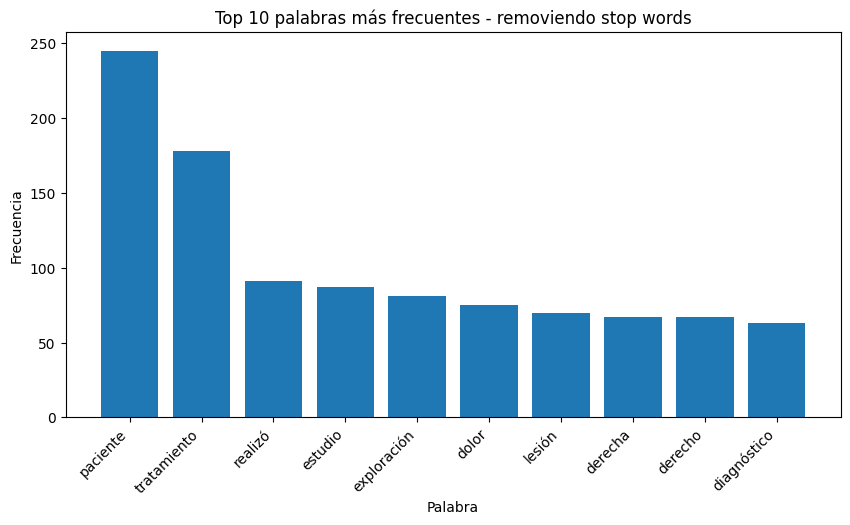

In [25]:
plot_top_words(top_all_raw, "Top 20 palabras más frecuentes - sin remover stop words")
plot_top_words(top_all_clean, "Top 10 palabras más frecuentes - removiendo stop words")

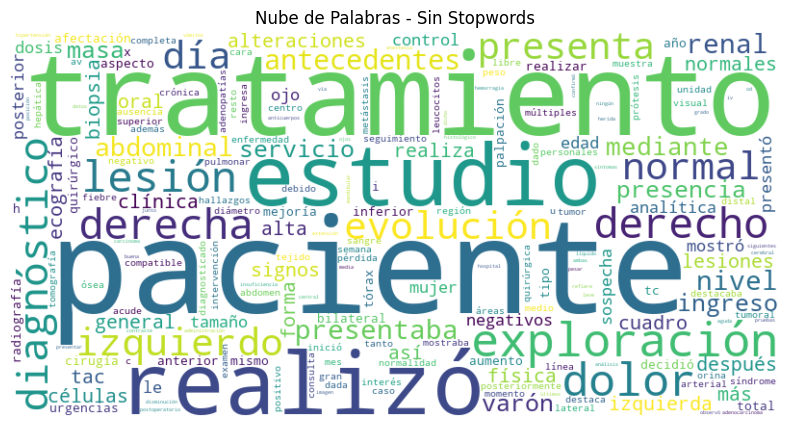

In [26]:
from wordcloud import WordCloud

# Obtener top palabras sin stopwords
top_words_clean = get_top_words(df_f["nota"], n=50000, remove_stopwords=True)

# Convertir a diccionario de frecuencias {palabra: conteo}
word_freq = dict(top_words_clean)

# Nube de palabras sin stopwords
wordcloud_clean = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate_from_frequencies(word_freq)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_clean, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras - Sin Stopwords')
plt.show()

In [28]:
def generate_ngram_wordcloud_criterio(df, criterio, ngram_size=2, stop_words=True):
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    for j, valor in enumerate([0, 1]):
        subset = df[df[criterio] == valor]["nota"].dropna()
        label = "Cumple" if valor == 1 else "No cumple"
        
        vectorizer = CountVectorizer(
            ngram_range=(ngram_size, ngram_size),
            stop_words=list(SPANISH_STOP_WORDS) if stop_words else None
        )
        
        X = vectorizer.fit_transform(subset)
        freqs = X.sum(axis=0)
        ngram_freq = {ngram: freqs[0, idx] for ngram, idx in vectorizer.vocabulary_.items()}
        
        if ngram_freq:
            wc = WordCloud(
                width=800, height=400,
                background_color='white'
            ).generate_from_frequencies(ngram_freq)
            axes[j].imshow(wc, interpolation='bilinear')
        
        axes[j].axis('off')
        axes[j].set_title(f'{criterio} — {label} (n={len(subset)})', fontsize=13)
    
    plt.suptitle(f'N-gramas ({ngram_size}) — {criterio}', fontsize=16)
    plt.tight_layout()
    plt.show()

## Exploracion de la variable objetivo

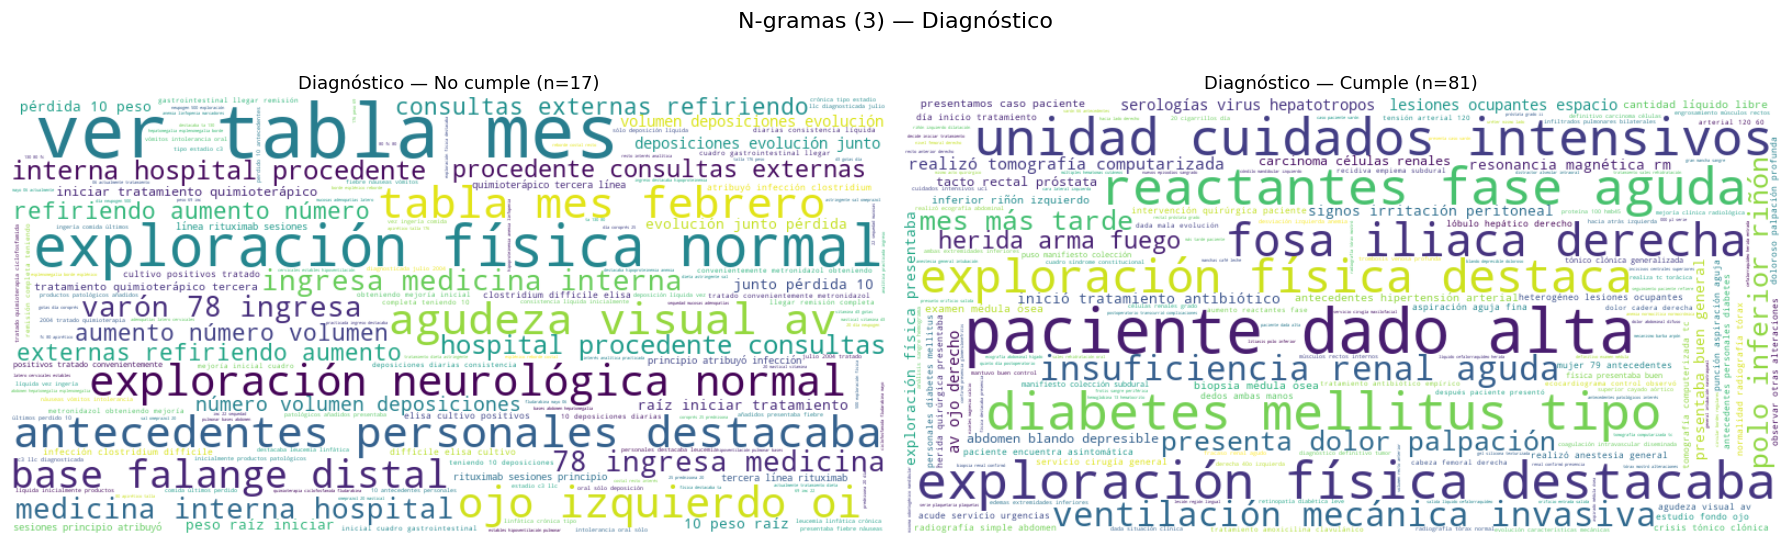

In [29]:
## Dagnostico

generate_ngram_wordcloud_criterio(
    df_f,
    criterio="Diagnóstico",
    ngram_size=3,
    stop_words=True
)

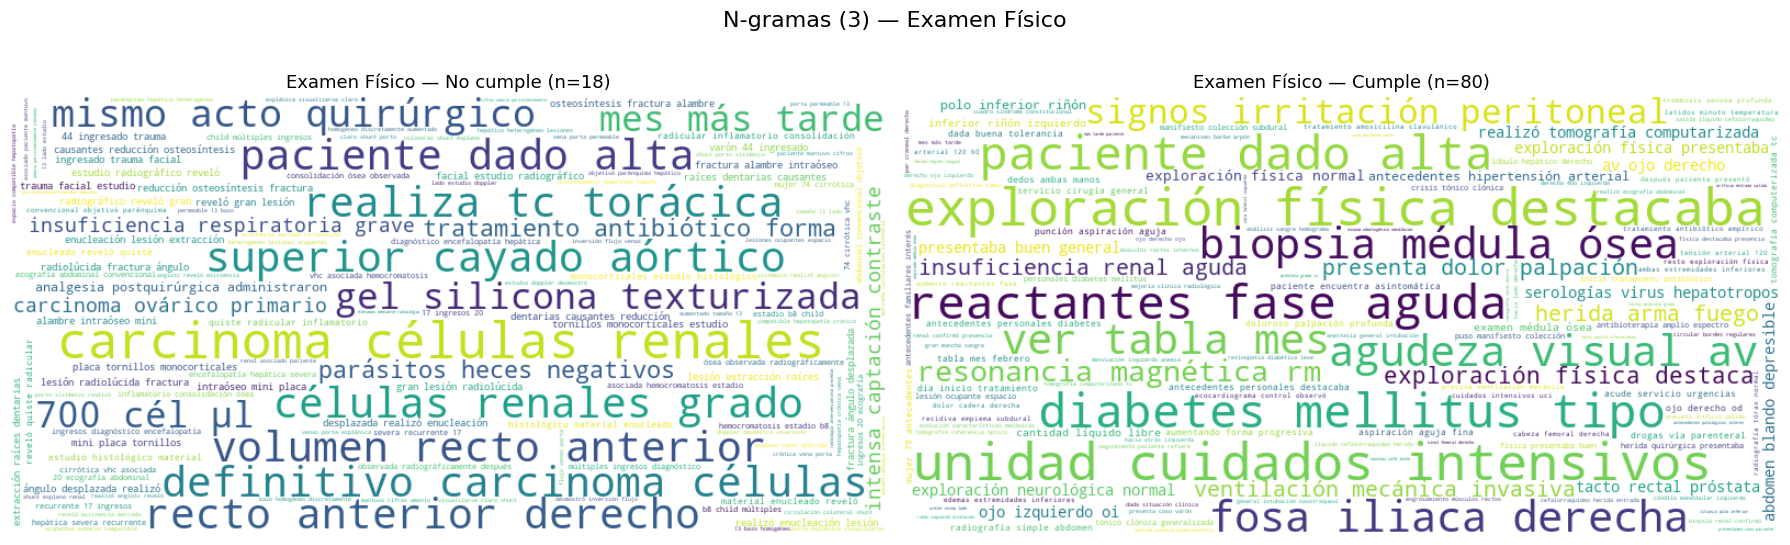

In [31]:
generate_ngram_wordcloud_criterio(
    df_f,
    criterio="Examen Físico",
    ngram_size=3,
    stop_words=True
)

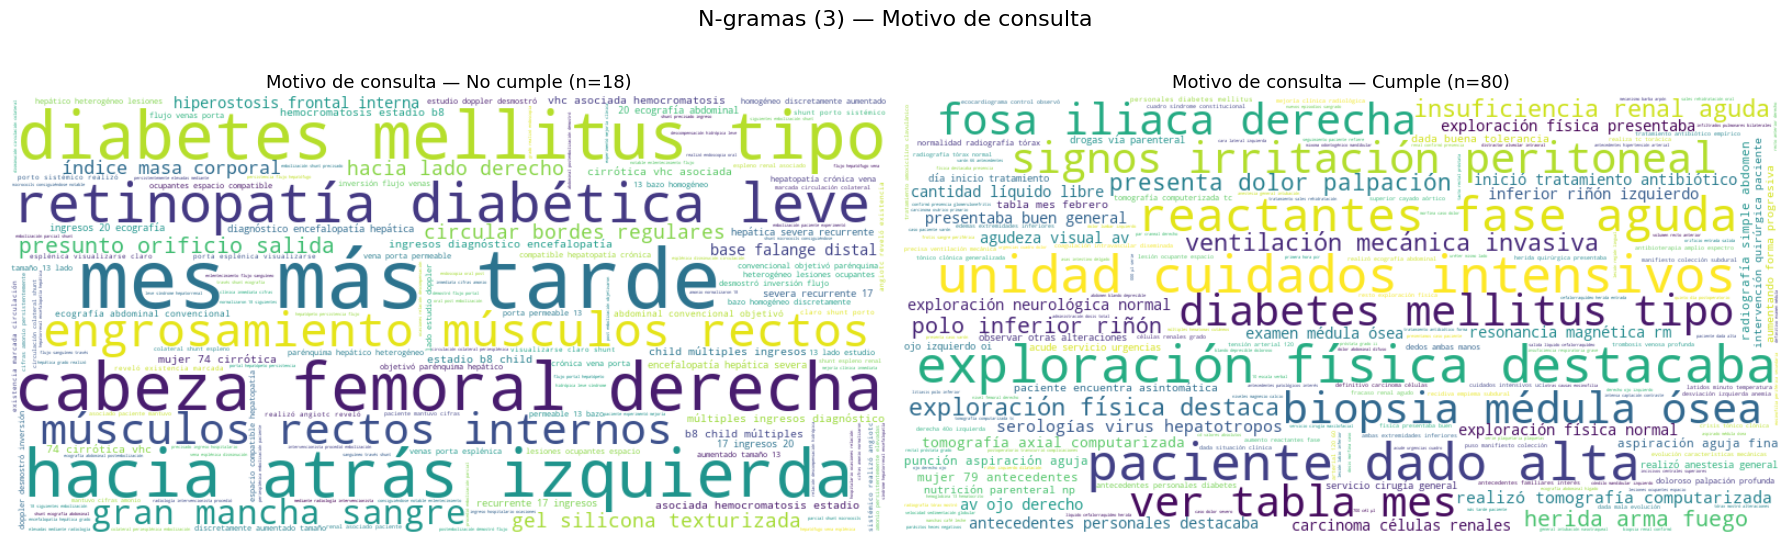

In [32]:
generate_ngram_wordcloud_criterio(
    df_f,
    criterio="Motivo de consulta",
    ngram_size=3,
    stop_words=True
)

In [33]:
all_tokens = []

for text in df_f["nota"].fillna("").astype(str):
    tokens = simple_tokenize(text)
    all_tokens.extend(tokens)

# Contar frecuencias
word_counts = Counter(all_tokens)

# Número total de palabras únicas
total_unique_words = len(word_counts)

# Palabras que aparecen una sola vez
words_once = [word for word, count in word_counts.items() if count == 1]
num_words_once = len(words_once)

# Ejemplos de palabras raras
rare_examples = words_once[:20]

print("Número total de palabras únicas:", total_unique_words)
print("Número de palabras que aparecen una sola vez:", num_words_once)
print("Ejemplos de palabras raras:")
print(rare_examples)

Número total de palabras únicas: 6224
Número de palabras que aparecen una sola vez: 3377
Ejemplos de palabras raras:
['traumático', 'aumentaba', 'manual', 'radiocarpiana', 'proximal', 'radiolucente', 'ovalada', 'excéntrica', 'encondroma', 'ganglión', 'epífisis', 'nacarado', 'vinosa', 'ocupaba', 'navicular', 'esponjoso', 'formado', 'matriz', 'cartilaginosa', 'pseudo']


Promedio de proporción de stop words: 0.442


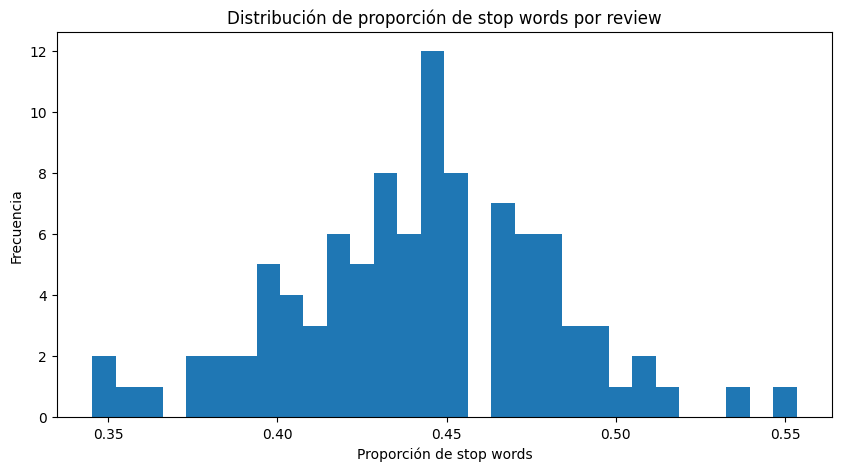

In [34]:
## proporcion de stopwords 

def stopword_ratio(text):
    tokens = simple_tokenize(text)
    if len(tokens) == 0:
        return 0
    stop_count = sum(1 for w in tokens if w in SPANISH_STOP_WORDS)
    return stop_count / len(tokens)

df_f["stopword_ratio"] = df_f["nota"].apply(stopword_ratio)

print("Promedio de proporción de stop words:", round(df_f["stopword_ratio"].mean(), 3))

plt.figure(figsize=(10, 5))
plt.hist(df_f["stopword_ratio"], bins=30)
plt.title("Distribución de proporción de stop words por review")
plt.xlabel("Proporción de stop words")
plt.ylabel("Frecuencia")
plt.show()

## Entranamiento LLM Clasificador de criterios





In [127]:
"""
Etiquetado automático de criterios de auditoría con LLM
=============================================================
Versión que lee los casos desde un archivo Excel (.xlsx),
procesa solo N casos y usa un único modelo de OpenRouter.

CONFIGURACIÓN:
  1. Pon tu API key en API_KEY (mejor: léela de una variable de entorno).
  2. Ajusta ARCHIVO_EXCEL con la ruta a tu .xlsx.
  3. Ajusta COLUMNA_TEXTO y COLUMNA_ID según los nombres de tus columnas.
  4. Instala las dependencias:  pip install openai pandas openpyxl tqdm requests
"""

import os
import json
import time
import pandas as pd
import requests
from tqdm import tqdm
from openai import OpenAI  # OpenRouter usa el mismo cliente de OpenAI

# ─────────────────────────────────────────────
# CONFIGURACIÓN — edita estos valores
# ─────────────────────────────────────────────
API_KEY        = os.getenv("OPENROUTER_API_KEY", "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")  # ⚠ no la subas a git
ARCHIVO_EXCEL  = "C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Audit HC (2).xlsx"
HOJA           = "Sheet1"                # nombre ("Hoja1") o índice (0) de la hoja
COLUMNA_TEXTO  = "nota"          # columna que contiene el caso clínico  ← AJUSTA
COLUMNA_ID     = "caso"           # columna con el ID del caso; pon None para usar el índice de fila  ← AJUSTA
N_CASOS        = 98              # cuántos casos procesar (los primeros N)
ARCHIVO_SALIDA = "./criterios_auditoria_pago exp1.csv"
MODELO         = "openai/gpt-4o-mini"  # un solo modelo gratuito
PAUSA_SEGUNDOS = 3.0
# ─────────────────────────────────────────────

client = OpenAI(
    api_key=API_KEY,
    base_url="https://openrouter.ai/api/v1"
)

PROMPT_SISTEMA = """
Eres un auditor médico experto. Tu tarea es evaluar casos clínicos en español
y determinar si cumplen ciertos criterios de calidad asistencial.

Debes responder ÚNICAMENTE con un objeto JSON válido, sin texto adicional,
sin explicaciones, sin comillas de bloque de código.

El formato exacto de respuesta es:
{
  "motivo_consulta": 0,
  "enfermedad_actual": 1,
  "examen_fisico": 0,
  "diagnostico": 1
}

Donde:
  1 = el criterio SÍ está presente en el texto
  0 = el criterio NO está presente en el texto
"""

PROMPT_USUARIO = """
Evalúa el siguiente caso clínico según estos 4 criterios:

1. motivo_consulta: ¿El texto menciona explícitamente el motivo o razón por la que el paciente consultó?
2. enfermedad_actual: ¿Se describe la evolución, historia o desarrollo de la enfermedad actual del paciente?
3. examen_fisico: ¿Se reportan hallazgos del examen físico realizado al paciente?
4. diagnostico: ¿Se establece un diagnóstico explícito en el texto?

CASO CLÍNICO:
{texto}

Responde solo con el JSON.
"""

ERROR_DICT = {"motivo_consulta": -1, "enfermedad_actual": -1, "examen_fisico": -1, "diagnostico": -1}


def listar_modelos_gratis(api_key: str) -> list:
    """Consulta el catálogo en vivo de OpenRouter y devuelve los IDs gratuitos (:free)."""
    try:
        r = requests.get(
            "https://openrouter.ai/api/v1/models",
            headers={"Authorization": f"Bearer {api_key}"},
            timeout=30,
        )
        modelos = r.json()["data"]
        return sorted(m["id"] for m in modelos if m["id"].endswith(":free"))
    except Exception as e:
        print(f"⚠ No se pudo consultar el catálogo de modelos: {e}")
        return []


def preparar_texto(texto: str) -> str:
    """Las notas caben completas en el contexto del modelo; no se recortan."""
    return texto


def llamar_modelo(texto_preparado: str, modelo: str) -> str | None:
    try:
        respuesta = client.chat.completions.create(
            model=modelo,
            temperature=0.3,
            max_tokens=1000,
            messages=[
                {"role": "system", "content": PROMPT_SISTEMA},
                {"role": "user",   "content": PROMPT_USUARIO.format(texto=texto_preparado)}
            ]
        )
        if not respuesta.choices or respuesta.choices[0].message.content is None:
            return None

        contenido = respuesta.choices[0].message.content.strip()
        # Algunos modelos de razonamiento devuelven un bloque <think>...</think>
        if "<think>" in contenido:
            fin_think = contenido.find("</think>")
            if fin_think != -1:
                contenido = contenido[fin_think + len("</think>"):].strip()

        return contenido if contenido else None

    except Exception as e:
        print(f"\n  ⚠ Excepción llamando al modelo: {e}")
        return None


def parsear_respuesta(respuesta_texto: str) -> dict | None:
    """Parsea el JSON de la respuesta. Retorna None si no es válido."""
    try:
        limpio = respuesta_texto.replace("```json", "").replace("```", "").strip()
        inicio = limpio.find("{")
        fin    = limpio.rfind("}") + 1
        if inicio == -1 or fin == 0:
            return None
        limpio = limpio[inicio:fin]

        criterios = json.loads(limpio)

        claves_esperadas = {"motivo_consulta", "enfermedad_actual", "examen_fisico", "diagnostico"}
        if not claves_esperadas.issubset(criterios.keys()):
            return None

        for clave in claves_esperadas:
            val = criterios[clave]
            criterios[clave] = 1 if str(val) in ["1", "true", "True"] else 0

        return criterios
    except Exception:
        return None


def evaluar_caso(texto: str, nombre_caso: str) -> dict:
    """Llama al LLM (un solo modelo) y retorna los 4 criterios.
    Reintenta una vez si la respuesta viene vacía o el JSON es inválido."""
    texto_preparado = preparar_texto(texto)

    for intento in range(2):  # un intento + un reintento
        respuesta_texto = llamar_modelo(texto_preparado, MODELO)

        if respuesta_texto is None:
            print(f"\n  ⚠ Respuesta vacía en {nombre_caso} (intento {intento + 1})")
            time.sleep(2)
            continue

        criterios = parsear_respuesta(respuesta_texto)
        if criterios is None:
            print(f"\n  ⚠ JSON inválido en {nombre_caso}: {respuesta_texto[:80]}")
            time.sleep(2)
            continue

        return criterios

    print(f"\n  ❌ Falló la evaluación de {nombre_caso}")
    return ERROR_DICT


def main():
    # Verificar archivo Excel
    if not os.path.exists(ARCHIVO_EXCEL):
        print(f"❌ No se encontró el archivo: {ARCHIVO_EXCEL}")
        return

    # Comprobar que el modelo está vivo (evita el error 404 "No endpoints found")
    # disponibles = listar_modelos_gratis(API_KEY)
    #if disponibles and MODELO not in disponibles:
    #    print(f"⚠ El modelo '{MODELO}' no aparece como disponible ahora mismo.")
    #    print(f"   Algunas opciones gratuitas actuales: {disponibles[:10]}")
    #    print("   Edita la variable MODELO y vuelve a ejecutar.\n")
    #    return

    # Leer Excel
    df_casos = pd.read_excel(ARCHIVO_EXCEL, sheet_name=HOJA)

    if COLUMNA_TEXTO not in df_casos.columns:
        print(f"❌ No existe la columna '{COLUMNA_TEXTO}' en el Excel.")
        print(f"   Columnas disponibles: {list(df_casos.columns)}")
        return

    # Tomar solo los primeros N casos
    df_casos = df_casos.head(N_CASOS).reset_index(drop=True)
    print(f"✅ {len(df_casos)} casos cargados desde el Excel")
    print(f"   Modelo: {MODELO}")
    print(f"   Salida: {ARCHIVO_SALIDA}\n")

    # Retomar si ya existe CSV parcial
    casos_procesados = set()
    resultados = []
    if os.path.exists(ARCHIVO_SALIDA):
        df_existente = pd.read_csv(ARCHIVO_SALIDA)
        casos_procesados = set(df_existente["caso"].astype(str).tolist())
        resultados = df_existente.to_dict("records")
        print(f"📂 Retomando: {len(casos_procesados)} casos ya procesados\n")

    # Procesar cada fila
    for i, fila_df in tqdm(df_casos.iterrows(), total=len(df_casos), desc="Evaluando criterios"):
        # Determinar el ID del caso
        if COLUMNA_ID and COLUMNA_ID in df_casos.columns:
            nombre = str(fila_df[COLUMNA_ID])
        else:
            nombre = f"caso_{i}"

        if nombre in casos_procesados:
            continue

        texto = fila_df[COLUMNA_TEXTO]
        if pd.isna(texto) or str(texto).strip() == "":
            print(f"\n  ⚠ Caso {nombre} sin texto, se marca como error")
            criterios = ERROR_DICT
        else:
            criterios = evaluar_caso(str(texto), nombre)

        resultados.append({"caso": nombre, **criterios})

        # Guardar cada 10 casos
        if len(resultados) % 10 == 0:
            pd.DataFrame(resultados).to_csv(ARCHIVO_SALIDA, index=False)

        time.sleep(PAUSA_SEGUNDOS)

    # Guardar CSV final
    df_final = pd.DataFrame(resultados)
    df_final.to_csv(ARCHIVO_SALIDA, index=False)

    # Resumen final
    df_validos = df_final[df_final["motivo_consulta"] != -1]
    print(f"\n{'='*55}")
    print(f"✅ Procesamiento completado")
    print(f"   Total casos procesados : {len(df_final)}")
    print(f"   Casos con error (-1)   : {len(df_final) - len(df_validos)}")
    print(f"   Archivo guardado en    : {ARCHIVO_SALIDA}")
    print(f"\n📊 Distribución de criterios (casos válidos):")
    print(f"   {'Criterio':<22} {'Cumple':>8} {'No cumple':>10} {'% cumple':>10}")
    print(f"   {'-'*52}")
    for criterio in ["motivo_consulta", "enfermedad_actual", "examen_fisico", "diagnostico"]:
        cumple    = (df_validos[criterio] == 1).sum()
        no_cumple = (df_validos[criterio] == 0).sum()
        pct       = round(cumple / len(df_validos) * 100, 1) if len(df_validos) > 0 else 0
        print(f"   {criterio:<22} {cumple:>8} {no_cumple:>10} {pct:>9}%")


if __name__ == "__main__":
    main()

✅ 98 casos cargados desde el Excel
   Modelo: openai/gpt-4o-mini
   Salida: ./criterios_auditoria_pago exp1.csv



Evaluando criterios: 100%|██████████| 98/98 [07:45<00:00,  4.75s/it]


✅ Procesamiento completado
   Total casos procesados : 98
   Casos con error (-1)   : 0
   Archivo guardado en    : ./criterios_auditoria_pago exp1.csv

📊 Distribución de criterios (casos válidos):
   Criterio                 Cumple  No cumple   % cumple
   ----------------------------------------------------
   motivo_consulta              85         13      86.7%
   enfermedad_actual            98          0     100.0%
   examen_fisico                78         20      79.6%
   diagnostico                  93          5      94.9%


## Costo de LLM

Se uso un modleo pago de openai gpt4

In [94]:
import requests
datos = requests.get("https://openrouter.ai/api/v1/models", timeout=30).json()["data"]
ids = {m["id"]: m for m in datos}

candidatos = ["google/gemini-2.5-flash", "openai/gpt-4o-mini",
              "deepseek/deepseek-chat-v3.1", "meta-llama/llama-3.3-70b-instruct",
              "qwen/qwen3-235b-a22b-2507"]
for c in candidatos:
    if c in ids:
        p = ids[c]["pricing"]
        print(f"{c:40} entrada ${float(p['prompt'])*1e6:.2f}/M  salida ${float(p['completion'])*1e6:.2f}/M")
    else:
        print(f"{c:40} → no disponible")

google/gemini-2.5-flash                  entrada $0.30/M  salida $2.50/M
openai/gpt-4o-mini                       entrada $0.15/M  salida $0.60/M
deepseek/deepseek-chat-v3.1              entrada $0.25/M  salida $0.95/M
meta-llama/llama-3.3-70b-instruct        entrada $0.59/M  salida $0.79/M
qwen/qwen3-235b-a22b-2507                entrada $0.09/M  salida $0.55/M


## comparacion y medicion de calidad del LLM con datos reales

Notas del experto: 98 | Notas del LLM: 98 | Emparejadas: 96


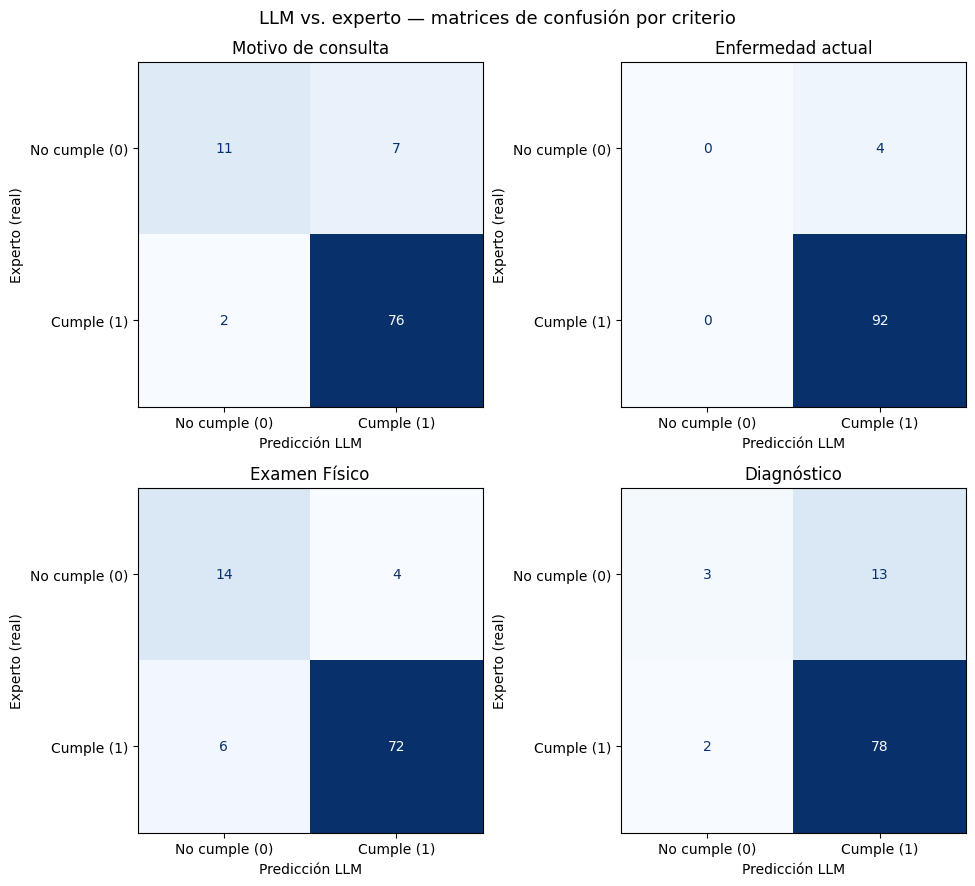

,n,Accuracy,Precision,Recall (Sens.),F1,F1 macro
Criterio,,,,,,
Motivo de consulta,96,0.906,0.916,0.974,0.944,0.827
Enfermedad actual,96,0.958,0.958,1.000,0.979,0.489
Examen Físico,96,0.896,0.947,0.923,0.935,0.836
Diagnóstico,96,0.844,0.857,0.975,0.912,0.599


In [128]:
# ── Comparación LLM vs. experto: matrices de confusión y métricas ──
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay)

# Nombre de la columna del experto  →  nombre de la columna del LLM
MAPA = {
    "Motivo de consulta": "motivo_consulta",
    "Enfermedad actual":  "enfermedad_actual",
    "Examen Físico":      "examen_fisico",
    "Diagnóstico":        "diagnostico",
}

df_llm = pd.read_csv(ARCHIVO_SALIDA, sep=None, engine="python")
df_llm["caso"] = df_llm["caso"].astype(str)

df_exp = df_evaluate[["caso"] + list(MAPA.keys())].copy()
df_exp["caso"] = df_exp["caso"].astype(str)
df_exp = df_exp.dropna(subset=list(MAPA.keys()))          # solo notas evaluadas por el experto
df_exp = df_exp.drop_duplicates(subset="caso")

df_comp = df_exp.merge(df_llm, on="caso", how="inner")
print(f"Notas del experto: {len(df_exp)} | Notas del LLM: {len(df_llm)} | Emparejadas: {len(df_comp)}")

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
filas = []

for ax, (col_exp, col_llm) in zip(axes.flat, MAPA.items()):
    d = df_comp[df_comp[col_llm] != -1]                   # excluye respuestas fallidas del LLM
    y_true = d[col_exp].astype(int)
    y_pred = d[col_llm].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No cumple (0)", "Cumple (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(col_exp)
    ax.set_xlabel("Predicción LLM")
    ax.set_ylabel("Experto (real)")

    tn, fp, fn, tp = cm.ravel()
    filas.append({
        "Criterio":        col_exp,
        "n":               len(d),
        "Accuracy":        accuracy_score(y_true, y_pred),
        "Precision":       precision_score(y_true, y_pred, zero_division=0),
        "Recall (Sens.)":  recall_score(y_true, y_pred, zero_division=0),
        "F1":              f1_score(y_true, y_pred, zero_division=0),
        "F1 macro":        f1_score(y_true, y_pred, average="macro", zero_division=0),
    })

plt.suptitle("LLM vs. experto — matrices de confusión por criterio", fontsize=13)
plt.tight_layout()
plt.show()

df_metricas = pd.DataFrame(filas).set_index("Criterio").round(3)
df_metricas



### LLM Clasificador con fewShots

In [109]:
"""
Etiquetado automático de criterios de auditoría con LLM — FEW-SHOT POR CRITERIO
===============================================================================
Cada nota se evalúa con 4 llamadas independientes, una por criterio. Cada llamada
recibe solo la regla de ese criterio y sus propios ejemplos resueltos, con el
razonamiento antes de la etiqueta.

CAMBIOS RESPECTO A LA VERSIÓN ANTERIOR:
  1. CRITERIOS: un diccionario con la regla, los ejemplos y el interruptor
     USAR_FEWSHOT de cada criterio.
  2. Cada ejemplo trae "razonamiento" para que el modelo aprenda el PORQUÉ.
  3. El modelo responde {"razonamiento": "...", "cumple": 0|1} por criterio.
  4. El CSV de salida guarda también el razonamiento de cada criterio
     (columnas <criterio>_razon) para revisar los errores.
  5. temperature = 0.
  6. La API key se lee SOLO de la variable de entorno.

CONFIGURACIÓN:
  pip install openai pandas openpyxl tqdm
  Define la variable de entorno OPENROUTER_API_KEY.
"""

import os
import json
import time
import pandas as pd
from tqdm import tqdm
from openai import OpenAI

# ─────────────────────────────────────────────
# CONFIGURACIÓN
# ─────────────────────────────────────────────
API_KEY        = os.getenv("OPENROUTER_API_KEY", "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")
ARCHIVO_EXCEL   = "C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Audit HC (2).xlsx"
HOJA            = "Sheet1"
COLUMNA_TEXTO   = "nota"
COLUMNA_ID      = "caso"
N_CASOS         = 98
ARCHIVO_SALIDA2  = "./criterios_auditoria_fewshot_por_criterio.csv"
MODELO          = "openai/gpt-4o-mini"
TEMPERATURA     = 0.3
PAUSA_SEGUNDOS  = 1.0          # pausa entre llamadas (ahora son 4 por nota)

# IDs de casos del Excel usados como ejemplos few-shot (se saltan al evaluar)
IDS_EJEMPLOS    = set()        # p. ej. {"12", "45", "78"}
# ─────────────────────────────────────────────

if not API_KEY:
    raise SystemExit("❌ Define la variable de entorno OPENROUTER_API_KEY")

client = OpenAI(api_key=API_KEY, base_url="https://openrouter.ai/api/v1")


# ─────────────────────────────────────────────
# NOTAS DE EJEMPLO (texto completo, se reutilizan en varios criterios)
# ─────────────────────────────────────────────
NOTA_AUTOPSIA = """Mujer de 18 años con antecedentes de síncope un mes antes del evento fatal, no habiendo consultado con ningún médico. Se encontraba sentada junto a su familia en la rivera de un río y súbitamente dice sentirse mal, pierde el conocimiento y cae al agua. Es recuperada del agua inmediatamente pero fallece a los pocos minutos. Inicialmente se sospecha que pudiera tratarse de una sumersión accidental.
La autopsia se realizó con un retraso postmortem de 16 horas. Se trataba del cadáver de una mujer de hábito atlético con una talla de 1,65 m y 54,5 kg de peso aproximadamente (IMC 20 kg/m2), sin signos externos de violencia ni hábito marfanoide.
A la apertura de la cavidad torácica se encontró un hemotórax izquierdo masivo de 3.000 cc debido a la rotura de un aneurisma sacular de la porción terminal del arco aórtico, ligeramente distal al origen de la arteria subclavia izquierda. Dicho aneurisma tenía unas medidas de 4,2 x 4,6 cm y su pared, notablemente adelgazada, a penas alcanzaba 1 mm de espesor. La línea de rotura medía 2 mm de longitud y se encontraba situada en la región infero-anterior del saco aneurismático.
El corazón tenía un peso de 200 g, siendo el peso esperado de 199 g, según tablas de Kitzman. A nivel del endocardio subaórtico se apreciaba un área clara ligeramente engrosada. Tanto las válvulas auriculoventriculares como las semilunares eran normales, al igual que el origen de las arterias coronarias.
El examen histopatológico de la pared del aneurisma mostró adelgazamiento de la pared de la aorta, a expensas de la rotura y la pérdida de las fibras elásticas y reducción del tejido muscular que se encontraba sustituido por una matriz basófila no fibrilar.
Ante la sospecha de la existencia de una colagenopatía atípica, es decir sin expresión fenotípica, se realizó screening genético de Síndrome de Marfan a la hermana menor de la fallecida -previo consejo genético en el Hospital del Niño-. La técnica utilizada fue la investigación genética molecular del marcador FBN1 que se amplificó por protocolo de PCR estándar, secuenciados y cuantificados mediante electroferogramas (electroforesis capilar), analizados y comparados con secuencias de referencia. El estudio resultó negativo. No se tamizaron otras enfermedades por carencia de los marcadores genéticos en ese momento."""

NOTA_HODGKIN = """Varón de 16 años de edad, en tratamiento quimioterápico por enfermedad de Hodgkin de carácter recidivante. En el curso de dicho tratamiento, el paciente mostró signos de hemorragia digestiva (melenas), acompañados de una intensa elevación de las transaminasas y una importante alteración en las pruebas de coagulación sanguínea (actividad de protombina). Dicho paciente falleció a los pocos días, por un cuadro de insuficiencia hepática aguda, con signos de encefalopatía y hemorragia digestiva masiva.
En la necropsia se observó un daño hepático difuso, acompañado de lesiones focales en el tercio inferior del esófago. El estudio histológico demostró, en ambos órganos, una lesión inflamatoria de carácter necrotizante, evidenciándose cambios citopáticos propios de infección herpética, consistentes en imágenes de multinucleación y presencia de cuerpos de Cowdry tipo A."""

NOTA_ECOENDOSCOPIA = """Se trata de un varón de 39 años de edad remitido a nuestra Unidad de Ecoendoscopia para filiar la naturaleza de una lesión submucosa localizada en la vertiente gástrica de la unión esófago-gástrica. El paciente inicia su estudio médico en el Servicio de Otorrinolaringología donde consulta por molestias faríngeas. Tras las exploraciones llevadas a cabo por este servicio se decide la realización de una endoscopia digestiva alta, donde se evidencia, a 36 cm de arcada dentaria, una lesión redondeada, con mucosa conservada de un diámetro mayor aproximado de 1,5 cm. Se toman biopsias mediante endoscopia, siendo el resultado histológico no concluyente. Ante la presencia de una lesión submucosa, cuya naturaleza no es posible filiar mediante la imagen endoscópica ni tras el estudio histológico de las biopsias se remite al paciente a nuestro centro para la realización de una ecoendoscopia (USE).
La USE se realiza de forma ambulatoria, bajo monitorización de constantes vitales y sedación consciente a base de midazolam y petidina. Se emplea un ecoendoscopio lineal Pentax EG3830UX acoplado a un ecógrafo Hitachi 8500. A 36 cm de arcada dentaria se identifica una pequeña lesión anecoica, bien delimitada, de aspecto quístico, que parece depender de la submucosa, de 14 x 6 mm de diámetros máximos. Mediante el estudio ultrasonográfico no se identifica la presencia de adenopatías abdominales ni mediastínicas y se demuestra la integridad del eje vascular. Una vez identificada la lesión a puncionar se realiza un estudio ecográfico con doppler color para evitar formaciones vasculares e identificar el trayecto más adecuado para realizar la punción. Para dicha punción se emplea la aguja Echotip Wilson-Cook de 19 G. En primer lugar se extrae la vaina de la aguja unos centímetros a través del canal de trabajo hasta ser visualizada bien gastroscópica- o ecoendoscópicamente; seguidamente se procede a puncionar la lesión mediante la aguja situada en el interior de la vaina. Una vez verificada su posición en el interior de la lesión, se retira el estilete (el cual se emplea para prevenir una posible contaminación de la muestra) y se realizan maniobras de avance de la aguja con el fin de extraer la mayor cantidad de material posible de la lesión. En nuestro caso hemos empleado una jeringa de aspiración para aumentar la celularidad de la muestra. Se realizan dos pases sobre la lesión hasta que el patólogo, presente en la sala de exploraciones, confirma la suficiencia de la muestra.
Se utiliza la tinción de Diff-Quick (Merck) para evaluar la muestra en la sala de exploraciones y se completa el estudio citológico con la tinción Papanicolau (Merck). En el examen citológico se evidencian abundantes histiocitos espumosos y escaso epitelio cilíndrico indicativo de quiste benigno compatible con quiste de duplicación gástrico."""


# ─────────────────────────────────────────────
# CRITERIOS: regla + ejemplos + interruptor few-shot
# ─────────────────────────────────────────────
# ⚠ Las reglas y los razonamientos son una propuesta: ajústalos con el experto.
CRITERIOS = {
    "motivo_consulta": {
        "nombre": "Motivo de consulta",
        "regla": (
            "Cumple (1): el texto indica explícitamente por qué el paciente consulta, "
            "ingresa o es remitido (síntoma, queja o razón de la atención).\n"
            "No cumple (0): no hay una consulta o atención con una razón identificable; "
            "por ejemplo, el texto solo narra un evento, un tratamiento en curso o una autopsia."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "La paciente nunca consultó a un médico; el texto narra un evento fatal y la autopsia.",
                "cumple": 0,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Se describe a un paciente ya en tratamiento y su evolución, pero no se indica por qué consulta o ingresa.",
                "cumple": 0,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "Se indica la razón de la atención: remitido para filiar una lesión submucosa, tras consultar por molestias faríngeas.",
                "cumple": 1,
            },
        ],
    },
    "enfermedad_actual": {
        "nombre": "Enfermedad actual",
        "regla": (
            "Cumple (1): se describe el cuadro clínico actual y su desarrollo "
            "(síntomas, tiempo de evolución, cómo ha cambiado o cómo se ha estudiado).\n"
            "No cumple (0): no se describe un cuadro clínico en curso; solo un evento aislado, "
            "antecedentes o hallazgos sin relato de la enfermedad."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "Solo se narra el evento agudo que precede a la muerte; no hay un cuadro clínico con síntomas y evolución.",
                "cumple": 0,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Describe la evolución del cuadro: melenas, elevación de transaminasas, alteración de la coagulación y progresión a insuficiencia hepática.",
                "cumple": 1,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "Relata el desarrollo del cuadro: molestias faríngeas, endoscopia con hallazgo de la lesión y biopsia no concluyente.",
                "cumple": 1,
            },
        ],
    },
    "examen_fisico": {
        "nombre": "Examen físico",
        "regla": (
            "Cumple (1): se reportan hallazgos de la exploración física externa del paciente "
            "(signos vitales con valores, talla, peso, inspección, hallazgos por sistemas).\n"
            "No cumple (0): no hay exploración física; solo laboratorio, imágenes, endoscopias, "
            "procedimientos, hallazgos de órganos internos o histología. Mencionar que se "
            "monitorizaron constantes sin dar hallazgos NO cuenta."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "Se describe la exploración externa del cuerpo: talla, peso, IMC, hábito y ausencia de signos externos de violencia.",
                "cumple": 1,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Solo hay datos de laboratorio, hallazgos de órganos internos en la necropsia e histología; no hay exploración física externa.",
                "cumple": 0,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "Solo se describen endoscopia, ecoendoscopia y citología; la monitorización de constantes no reporta ningún hallazgo.",
                "cumple": 0,
            },
        ],
    },
    "diagnostico": {
        "nombre": "Diagnóstico",
        "regla": (
            "Cumple (1): se establece explícitamente al menos un diagnóstico (impresión "
            "diagnóstica, diagnóstico principal, causa establecida o código CIE-10).\n"
            "No cumple (0): solo hay hallazgos, resultados o tratamientos sin diagnóstico "
            "establecido, o el diagnóstico queda como sospecha o como 'compatible con'."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "Se describen hallazgos de autopsia e histología y una sospecha de colagenopatía que no se confirma; no se establece un diagnóstico.",
                "cumple": 0,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Se establece el diagnóstico: insuficiencia hepática aguda por infección herpética demostrada en la histología.",
                "cumple": 1,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "La citología es solo 'compatible con' quiste de duplicación gástrico; queda como impresión no establecida.",
                "cumple": 0,
            },
        ],
    },
}

LISTA_CRITERIOS = list(CRITERIOS.keys())


# ─────────────────────────────────────────────
# PROMPTS
# ─────────────────────────────────────────────
def prompt_sistema(criterio: str) -> str:
    c = CRITERIOS[criterio]
    return f"""Eres un auditor médico experto. Evalúas notas clínicas en español.
Tu tarea es evaluar ÚNICAMENTE el criterio: {c['nombre']}.

Regla:
{c['regla']}

Primero razona brevemente (una o dos frases) y luego decide.
Responde ÚNICAMENTE con un objeto JSON válido, sin texto adicional ni bloques de código:
{{"razonamiento": "<una o dos frases>", "cumple": <0 o 1>}}"""


PROMPT_USUARIO = """CASO CLÍNICO:
{texto}

Responde solo con el JSON."""


def construir_mensajes(criterio: str, texto_caso: str) -> list:
    """System del criterio + (ejemplo user → respuesta assistant) x N + caso real."""
    c = CRITERIOS[criterio]
    mensajes = [{"role": "system", "content": prompt_sistema(criterio)}]
    if c["usar_fewshot"]:
        for ej in c["ejemplos"]:
            mensajes.append({"role": "user", "content": PROMPT_USUARIO.format(texto=ej["texto"])})
            respuesta = {"razonamiento": ej["razonamiento"], "cumple": ej["cumple"]}
            mensajes.append({"role": "assistant", "content": json.dumps(respuesta, ensure_ascii=False)})
    mensajes.append({"role": "user", "content": PROMPT_USUARIO.format(texto=texto_caso)})
    return mensajes


# ─────────────────────────────────────────────
# LLAMADA AL MODELO Y PARSEO
# ─────────────────────────────────────────────
def llamar_modelo(mensajes: list) -> str | None:
    try:
        respuesta = client.chat.completions.create(
            model=MODELO,
            temperature=TEMPERATURA,
            max_tokens=1000,
            messages=mensajes,
        )
        if not respuesta.choices or respuesta.choices[0].message.content is None:
            return None
        contenido = respuesta.choices[0].message.content.strip()
        if "<think>" in contenido:
            fin_think = contenido.find("</think>")
            if fin_think != -1:
                contenido = contenido[fin_think + len("</think>"):].strip()
        return contenido or None
    except Exception as e:
        print(f"\n  ⚠ Excepción llamando al modelo: {e}")
        return None


def parsear_respuesta(respuesta_texto: str) -> tuple[int, str] | None:
    try:
        limpio = respuesta_texto.replace("```json", "").replace("```", "").strip()
        inicio, fin = limpio.find("{"), limpio.rfind("}") + 1
        if inicio == -1 or fin == 0:
            return None
        datos = json.loads(limpio[inicio:fin])
        if "cumple" not in datos:
            return None
        valor = 1 if str(datos["cumple"]).strip() in ["1", "true", "True"] else 0
        return valor, str(datos.get("razonamiento", ""))
    except Exception:
        return None


def evaluar_criterio(criterio: str, texto: str, nombre_caso: str) -> tuple[int, str]:
    mensajes = construir_mensajes(criterio, texto)
    for intento in range(2):
        respuesta_texto = llamar_modelo(mensajes)
        if respuesta_texto is None:
            print(f"\n  ⚠ Respuesta vacía en {nombre_caso}/{criterio} (intento {intento + 1})")
            time.sleep(2)
            continue
        resultado = parsear_respuesta(respuesta_texto)
        if resultado is None:
            print(f"\n  ⚠ JSON inválido en {nombre_caso}/{criterio}: {respuesta_texto[:80]}")
            time.sleep(2)
            continue
        return resultado
    print(f"\n  ❌ Falló {nombre_caso}/{criterio}")
    return -1, ""


def evaluar_caso(texto: str, nombre_caso: str) -> dict:
    fila = {}
    for criterio in LISTA_CRITERIOS:
        valor, razon = evaluar_criterio(criterio, texto, nombre_caso)
        fila[criterio] = valor
        fila[f"{criterio}_razon"] = razon
        time.sleep(PAUSA_SEGUNDOS)
    return fila


# ─────────────────────────────────────────────
# PROGRAMA PRINCIPAL
# ─────────────────────────────────────────────
def main():
    if not os.path.exists(ARCHIVO_EXCEL):
        print(f"❌ No se encontró el archivo: {ARCHIVO_EXCEL}")
        return

    df_casos = pd.read_excel(ARCHIVO_EXCEL, sheet_name=HOJA)
    if COLUMNA_TEXTO not in df_casos.columns:
        print(f"❌ No existe la columna '{COLUMNA_TEXTO}'. Disponibles: {list(df_casos.columns)}")
        return

    df_casos = df_casos.head(N_CASOS).reset_index(drop=True)
    modo = {c: ("few-shot" if CRITERIOS[c]["usar_fewshot"] else "zero-shot") for c in LISTA_CRITERIOS}
    print(f"✅ {len(df_casos)} casos cargados | Modelo: {MODELO}")
    print(f"   Modo por criterio: {modo}\n")

    casos_procesados, resultados = set(), []
    if os.path.exists(ARCHIVO_SALIDA2):
        df_existente = pd.read_csv(ARCHIVO_SALIDA2)
        casos_procesados = set(df_existente["caso"].astype(str))
        resultados = df_existente.to_dict("records")
        print(f"📂 Retomando: {len(casos_procesados)} casos ya procesados\n")

    for i, fila in tqdm(df_casos.iterrows(), total=len(df_casos), desc="Evaluando criterios"):
        nombre = str(fila[COLUMNA_ID]) if COLUMNA_ID and COLUMNA_ID in df_casos.columns else f"caso_{i}"

        if nombre in casos_procesados or nombre in IDS_EJEMPLOS:
            continue

        texto = fila[COLUMNA_TEXTO]
        if pd.isna(texto) or str(texto).strip() == "":
            print(f"\n  ⚠ Caso {nombre} sin texto, se marca como error")
            criterios = {}
            for c in LISTA_CRITERIOS:
                criterios[c] = -1
                criterios[f"{c}_razon"] = ""
        else:
            criterios = evaluar_caso(str(texto), nombre)

        resultados.append({"caso": nombre, **criterios})
        if len(resultados) % 10 == 0:
            pd.DataFrame(resultados).to_csv(ARCHIVO_SALIDA2, index=False)

    df_final = pd.DataFrame(resultados)
    df_final.to_csv(ARCHIVO_SALIDA2, index=False)

    print(f"\n{'=' * 60}\n✅ Procesamiento completado")
    print(f"   Total casos procesados : {len(df_final)}")
    print(f"   Archivo guardado en    : {ARCHIVO_SALIDA2}")
    print(f"\n📊 Distribución por criterio:")
    print(f"   {'Criterio':<22} {'Cumple':>8} {'No cumple':>10} {'Error':>7} {'% cumple':>10}")
    print(f"   {'-' * 60}")
    for c in LISTA_CRITERIOS:
        cumple = (df_final[c] == 1).sum()
        no_cumple = (df_final[c] == 0).sum()
        errores = (df_final[c] == -1).sum()
        validos = cumple + no_cumple
        pct = round(cumple / validos * 100, 1) if validos else 0
        print(f"   {c:<22} {cumple:>8} {no_cumple:>10} {errores:>7} {pct:>9}%")


if __name__ == "__main__":
    main()

✅ 98 casos cargados | Modelo: openai/gpt-4o-mini
   Modo por criterio: {'motivo_consulta': 'few-shot', 'enfermedad_actual': 'few-shot', 'examen_fisico': 'few-shot', 'diagnostico': 'few-shot'}

📂 Retomando: 70 casos ya procesados



Evaluando criterios: 100%|██████████| 98/98 [03:43<00:00,  2.28s/it]


✅ Procesamiento completado
   Total casos procesados : 98
   Archivo guardado en    : ./criterios_auditoria_fewshot_por_criterio.csv

📊 Distribución por criterio:
   Criterio                 Cumple  No cumple   Error   % cumple
   ------------------------------------------------------------
   motivo_consulta              74         24       0      75.5%
   enfermedad_actual            89          9       0      90.8%
   examen_fisico                75         23       0      76.5%
   diagnostico                  73         25       0      74.5%


## comparacion y medicion de calidad del LLM con fewshot con datos reales

Notas del experto: 98 | Notas del LLM: 98 | Emparejadas: 96


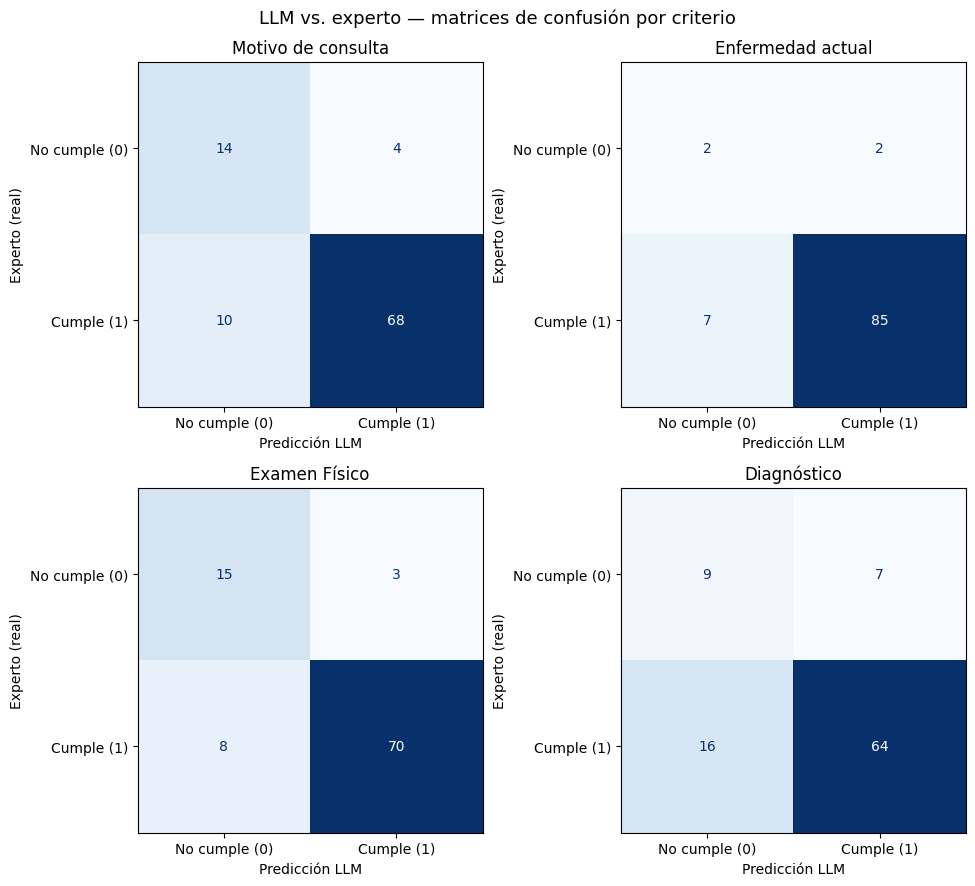

,n,Accuracy,Precision,Recall (Sens.),F1,F1 macro
Criterio,,,,,,
Motivo de consulta,96,0.854,0.944,0.872,0.907,0.787
Enfermedad actual,96,0.906,0.977,0.924,0.950,0.629
Examen Físico,96,0.885,0.959,0.897,0.927,0.829
Diagnóstico,96,0.760,0.901,0.800,0.848,0.643


In [110]:
# ── Comparación LLM vs. experto: matrices de confusión y métricas ──
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay)

# Nombre de la columna del experto  →  nombre de la columna del LLM
MAPA = {
    "Motivo de consulta": "motivo_consulta",
    "Enfermedad actual":  "enfermedad_actual",
    "Examen Físico":      "examen_fisico",
    "Diagnóstico":        "diagnostico",
}

df_llm = pd.read_csv(ARCHIVO_SALIDA2, sep=None, engine="python")
df_llm["caso"] = df_llm["caso"].astype(str)

df_exp = df_evaluate[["caso"] + list(MAPA.keys())].copy()
df_exp["caso"] = df_exp["caso"].astype(str)
df_exp = df_exp.dropna(subset=list(MAPA.keys()))          # solo notas evaluadas por el experto
df_exp = df_exp.drop_duplicates(subset="caso")

df_comp = df_exp.merge(df_llm, on="caso", how="inner")
print(f"Notas del experto: {len(df_exp)} | Notas del LLM: {len(df_llm)} | Emparejadas: {len(df_comp)}")

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
filas = []

for ax, (col_exp, col_llm) in zip(axes.flat, MAPA.items()):
    d = df_comp[df_comp[col_llm] != -1]                   # excluye respuestas fallidas del LLM
    y_true = d[col_exp].astype(int)
    y_pred = d[col_llm].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No cumple (0)", "Cumple (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(col_exp)
    ax.set_xlabel("Predicción LLM")
    ax.set_ylabel("Experto (real)")

    tn, fp, fn, tp = cm.ravel()
    filas.append({
        "Criterio":        col_exp,
        "n":               len(d),
        "Accuracy":        accuracy_score(y_true, y_pred),
        "Precision":       precision_score(y_true, y_pred, zero_division=0),
        "Recall (Sens.)":  recall_score(y_true, y_pred, zero_division=0),
        "F1":              f1_score(y_true, y_pred, zero_division=0),
        "F1 macro":        f1_score(y_true, y_pred, average="macro", zero_division=0),
    })

plt.suptitle("LLM vs. experto — matrices de confusión por criterio", fontsize=13)
plt.tight_layout()
plt.show()

df_metricas = pd.DataFrame(filas).set_index("Criterio").round(3)
df_metricas


Motivo de consulta: el LLM funciona bien. Solo tiene 7 errores de 101, repartidos de forma equilibrada

Examen físico: el LLM se equivoca por omisión. En 19 notas el experto dice que sí hay examen físico y el LLM dice que no, mientras que al revés solo se equivoca en 2. Hay una causa técnica probable en tu código: la función preparar_texto. Cuando una nota pasa de 3.000 caracteres, al LLM solo le llegan los primeros 500 y los últimos 500 caracteres, porque toma el primer y el último fragmento. El examen físico suele estar en la mitad de la nota, así que en las notas largas el modelo nunca lo ve. Tus notas tienen en promedio 360 palabras, que son unos 2.200 caracteres, así que una buena parte pasa de ese límite.

Diagnóstico: el LLM es demasiado permisivo. De las 19 notas que el experto marcó como "no cumple", el LLM aprobó 16. Eso sugiere que el experto usa un criterio más estricto (por ejemplo, un diagnóstico final explícito y bien formulado), mientras que el LLM acepta cualquier mención de una enfermedad. Es un problema de definición en el prompt, no del modelo.


### reproducibilidad del mejor modelo

In [120]:
"""
Etiquetado automático de criterios de auditoría con LLM — FEW-SHOT POR CRITERIO
===============================================================================
Cada nota se evalúa con 4 llamadas independientes, una por criterio. Cada llamada
recibe solo la regla de ese criterio y sus propios ejemplos resueltos, con el
razonamiento antes de la etiqueta.

CAMBIOS RESPECTO A LA VERSIÓN ANTERIOR:
  1. CRITERIOS: un diccionario con la regla, los ejemplos y el interruptor
     USAR_FEWSHOT de cada criterio.
  2. Cada ejemplo trae "razonamiento" para que el modelo aprenda el PORQUÉ.
  3. El modelo responde {"razonamiento": "...", "cumple": 0|1} por criterio.
  4. El CSV de salida guarda también el razonamiento de cada criterio
     (columnas <criterio>_razon) para revisar los errores.
  5. temperature = 0.
  6. La API key se lee SOLO de la variable de entorno.

CONFIGURACIÓN:
  pip install openai pandas openpyxl tqdm
  Define la variable de entorno OPENROUTER_API_KEY.
"""

import os
import json
import time
import pandas as pd
from tqdm import tqdm
from openai import OpenAI

# ─────────────────────────────────────────────
# CONFIGURACIÓN
# ─────────────────────────────────────────────
API_KEY        = os.getenv("OPENROUTER_API_KEY", "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")
ARCHIVO_EXCEL   = "C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Reproducibilidad.xlsx"
HOJA            = "Hoja1"
COLUMNA_TEXTO   = "nota"
COLUMNA_ID      = "caso"
N_CASOS         = 899
ARCHIVO_SALIDA2  = "./criterios_auditoria_fewshot_por_criterio.csv"
MODELO          = "openai/gpt-4o-mini"
TEMPERATURA     = 0.3
PAUSA_SEGUNDOS  = 1.0          # pausa entre llamadas (ahora son 4 por nota)

# IDs de casos del Excel usados como ejemplos few-shot (se saltan al evaluar)
IDS_EJEMPLOS    = set()        # p. ej. {"12", "45", "78"}
# ─────────────────────────────────────────────

if not API_KEY:
    raise SystemExit("❌ Define la variable de entorno OPENROUTER_API_KEY")

client = OpenAI(api_key=API_KEY, base_url="https://openrouter.ai/api/v1")


# ─────────────────────────────────────────────
# NOTAS DE EJEMPLO (texto completo, se reutilizan en varios criterios)
# ─────────────────────────────────────────────
NOTA_AUTOPSIA = """Mujer de 18 años con antecedentes de síncope un mes antes del evento fatal, no habiendo consultado con ningún médico. Se encontraba sentada junto a su familia en la rivera de un río y súbitamente dice sentirse mal, pierde el conocimiento y cae al agua. Es recuperada del agua inmediatamente pero fallece a los pocos minutos. Inicialmente se sospecha que pudiera tratarse de una sumersión accidental.
La autopsia se realizó con un retraso postmortem de 16 horas. Se trataba del cadáver de una mujer de hábito atlético con una talla de 1,65 m y 54,5 kg de peso aproximadamente (IMC 20 kg/m2), sin signos externos de violencia ni hábito marfanoide.
A la apertura de la cavidad torácica se encontró un hemotórax izquierdo masivo de 3.000 cc debido a la rotura de un aneurisma sacular de la porción terminal del arco aórtico, ligeramente distal al origen de la arteria subclavia izquierda. Dicho aneurisma tenía unas medidas de 4,2 x 4,6 cm y su pared, notablemente adelgazada, a penas alcanzaba 1 mm de espesor. La línea de rotura medía 2 mm de longitud y se encontraba situada en la región infero-anterior del saco aneurismático.
El corazón tenía un peso de 200 g, siendo el peso esperado de 199 g, según tablas de Kitzman. A nivel del endocardio subaórtico se apreciaba un área clara ligeramente engrosada. Tanto las válvulas auriculoventriculares como las semilunares eran normales, al igual que el origen de las arterias coronarias.
El examen histopatológico de la pared del aneurisma mostró adelgazamiento de la pared de la aorta, a expensas de la rotura y la pérdida de las fibras elásticas y reducción del tejido muscular que se encontraba sustituido por una matriz basófila no fibrilar.
Ante la sospecha de la existencia de una colagenopatía atípica, es decir sin expresión fenotípica, se realizó screening genético de Síndrome de Marfan a la hermana menor de la fallecida -previo consejo genético en el Hospital del Niño-. La técnica utilizada fue la investigación genética molecular del marcador FBN1 que se amplificó por protocolo de PCR estándar, secuenciados y cuantificados mediante electroferogramas (electroforesis capilar), analizados y comparados con secuencias de referencia. El estudio resultó negativo. No se tamizaron otras enfermedades por carencia de los marcadores genéticos en ese momento."""

NOTA_HODGKIN = """Varón de 16 años de edad, en tratamiento quimioterápico por enfermedad de Hodgkin de carácter recidivante. En el curso de dicho tratamiento, el paciente mostró signos de hemorragia digestiva (melenas), acompañados de una intensa elevación de las transaminasas y una importante alteración en las pruebas de coagulación sanguínea (actividad de protombina). Dicho paciente falleció a los pocos días, por un cuadro de insuficiencia hepática aguda, con signos de encefalopatía y hemorragia digestiva masiva.
En la necropsia se observó un daño hepático difuso, acompañado de lesiones focales en el tercio inferior del esófago. El estudio histológico demostró, en ambos órganos, una lesión inflamatoria de carácter necrotizante, evidenciándose cambios citopáticos propios de infección herpética, consistentes en imágenes de multinucleación y presencia de cuerpos de Cowdry tipo A."""

NOTA_ECOENDOSCOPIA = """Se trata de un varón de 39 años de edad remitido a nuestra Unidad de Ecoendoscopia para filiar la naturaleza de una lesión submucosa localizada en la vertiente gástrica de la unión esófago-gástrica. El paciente inicia su estudio médico en el Servicio de Otorrinolaringología donde consulta por molestias faríngeas. Tras las exploraciones llevadas a cabo por este servicio se decide la realización de una endoscopia digestiva alta, donde se evidencia, a 36 cm de arcada dentaria, una lesión redondeada, con mucosa conservada de un diámetro mayor aproximado de 1,5 cm. Se toman biopsias mediante endoscopia, siendo el resultado histológico no concluyente. Ante la presencia de una lesión submucosa, cuya naturaleza no es posible filiar mediante la imagen endoscópica ni tras el estudio histológico de las biopsias se remite al paciente a nuestro centro para la realización de una ecoendoscopia (USE).
La USE se realiza de forma ambulatoria, bajo monitorización de constantes vitales y sedación consciente a base de midazolam y petidina. Se emplea un ecoendoscopio lineal Pentax EG3830UX acoplado a un ecógrafo Hitachi 8500. A 36 cm de arcada dentaria se identifica una pequeña lesión anecoica, bien delimitada, de aspecto quístico, que parece depender de la submucosa, de 14 x 6 mm de diámetros máximos. Mediante el estudio ultrasonográfico no se identifica la presencia de adenopatías abdominales ni mediastínicas y se demuestra la integridad del eje vascular. Una vez identificada la lesión a puncionar se realiza un estudio ecográfico con doppler color para evitar formaciones vasculares e identificar el trayecto más adecuado para realizar la punción. Para dicha punción se emplea la aguja Echotip Wilson-Cook de 19 G. En primer lugar se extrae la vaina de la aguja unos centímetros a través del canal de trabajo hasta ser visualizada bien gastroscópica- o ecoendoscópicamente; seguidamente se procede a puncionar la lesión mediante la aguja situada en el interior de la vaina. Una vez verificada su posición en el interior de la lesión, se retira el estilete (el cual se emplea para prevenir una posible contaminación de la muestra) y se realizan maniobras de avance de la aguja con el fin de extraer la mayor cantidad de material posible de la lesión. En nuestro caso hemos empleado una jeringa de aspiración para aumentar la celularidad de la muestra. Se realizan dos pases sobre la lesión hasta que el patólogo, presente en la sala de exploraciones, confirma la suficiencia de la muestra.
Se utiliza la tinción de Diff-Quick (Merck) para evaluar la muestra en la sala de exploraciones y se completa el estudio citológico con la tinción Papanicolau (Merck). En el examen citológico se evidencian abundantes histiocitos espumosos y escaso epitelio cilíndrico indicativo de quiste benigno compatible con quiste de duplicación gástrico."""


# ─────────────────────────────────────────────
# CRITERIOS: regla + ejemplos + interruptor few-shot
# ─────────────────────────────────────────────
# ⚠ Las reglas y los razonamientos son una propuesta: ajústalos con el experto.
CRITERIOS = {
    "motivo_consulta": {
        "nombre": "Motivo de consulta",
        "regla": (
            "Cumple (1): el texto indica explícitamente por qué el paciente consulta, "
            "ingresa o es remitido (síntoma, queja o razón de la atención).\n"
            "No cumple (0): no hay una consulta o atención con una razón identificable; "
            "por ejemplo, el texto solo narra un evento, un tratamiento en curso o una autopsia."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "La paciente nunca consultó a un médico; el texto narra un evento fatal y la autopsia.",
                "cumple": 0,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Se describe a un paciente ya en tratamiento y su evolución, pero no se indica por qué consulta o ingresa.",
                "cumple": 0,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "Se indica la razón de la atención: remitido para filiar una lesión submucosa, tras consultar por molestias faríngeas.",
                "cumple": 1,
            },
        ],
    },
    "enfermedad_actual": {
        "nombre": "Enfermedad actual",
        "regla": (
            "Cumple (1): se describe el cuadro clínico actual y su desarrollo "
            "(síntomas, tiempo de evolución, cómo ha cambiado o cómo se ha estudiado).\n"
            "No cumple (0): no se describe un cuadro clínico en curso; solo un evento aislado, "
            "antecedentes o hallazgos sin relato de la enfermedad."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "Solo se narra el evento agudo que precede a la muerte; no hay un cuadro clínico con síntomas y evolución.",
                "cumple": 0,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Describe la evolución del cuadro: melenas, elevación de transaminasas, alteración de la coagulación y progresión a insuficiencia hepática.",
                "cumple": 1,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "Relata el desarrollo del cuadro: molestias faríngeas, endoscopia con hallazgo de la lesión y biopsia no concluyente.",
                "cumple": 1,
            },
        ],
    },
    "examen_fisico": {
        "nombre": "Examen físico",
        "regla": (
            "Cumple (1): se reportan hallazgos de la exploración física externa del paciente "
            "(signos vitales con valores, talla, peso, inspección, hallazgos por sistemas).\n"
            "No cumple (0): no hay exploración física; solo laboratorio, imágenes, endoscopias, "
            "procedimientos, hallazgos de órganos internos o histología. Mencionar que se "
            "monitorizaron constantes sin dar hallazgos NO cuenta."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "Se describe la exploración externa del cuerpo: talla, peso, IMC, hábito y ausencia de signos externos de violencia.",
                "cumple": 1,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Solo hay datos de laboratorio, hallazgos de órganos internos en la necropsia e histología; no hay exploración física externa.",
                "cumple": 0,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "Solo se describen endoscopia, ecoendoscopia y citología; la monitorización de constantes no reporta ningún hallazgo.",
                "cumple": 0,
            },
        ],
    },
    "diagnostico": {
        "nombre": "Diagnóstico",
        "regla": (
            "Cumple (1): se establece explícitamente al menos un diagnóstico (impresión "
            "diagnóstica, diagnóstico principal, causa establecida o código CIE-10).\n"
            "No cumple (0): solo hay hallazgos, resultados o tratamientos sin diagnóstico "
            "establecido, o el diagnóstico queda como sospecha o como 'compatible con'."
        ),
        "usar_fewshot": True,
        "ejemplos": [
            {
                "texto": NOTA_AUTOPSIA,
                "razonamiento": "Se describen hallazgos de autopsia e histología y una sospecha de colagenopatía que no se confirma; no se establece un diagnóstico.",
                "cumple": 0,
            },
            {
                "texto": NOTA_HODGKIN,
                "razonamiento": "Se establece el diagnóstico: insuficiencia hepática aguda por infección herpética demostrada en la histología.",
                "cumple": 1,
            },
            {
                "texto": NOTA_ECOENDOSCOPIA,
                "razonamiento": "La citología es solo 'compatible con' quiste de duplicación gástrico; queda como impresión no establecida.",
                "cumple": 0,
            },
        ],
    },
}

LISTA_CRITERIOS = list(CRITERIOS.keys())


# ─────────────────────────────────────────────
# PROMPTS
# ─────────────────────────────────────────────
def prompt_sistema(criterio: str) -> str:
    c = CRITERIOS[criterio]
    return f"""Eres un auditor médico experto. Evalúas notas clínicas en español.
Tu tarea es evaluar ÚNICAMENTE el criterio: {c['nombre']}.

Regla:
{c['regla']}

Primero razona brevemente (una o dos frases) y luego decide.
Responde ÚNICAMENTE con un objeto JSON válido, sin texto adicional ni bloques de código:
{{"razonamiento": "<una o dos frases>", "cumple": <0 o 1>}}"""


PROMPT_USUARIO = """CASO CLÍNICO:
{texto}

Responde solo con el JSON."""


def construir_mensajes(criterio: str, texto_caso: str) -> list:
    """System del criterio + (ejemplo user → respuesta assistant) x N + caso real."""
    c = CRITERIOS[criterio]
    mensajes = [{"role": "system", "content": prompt_sistema(criterio)}]
    if c["usar_fewshot"]:
        for ej in c["ejemplos"]:
            mensajes.append({"role": "user", "content": PROMPT_USUARIO.format(texto=ej["texto"])})
            respuesta = {"razonamiento": ej["razonamiento"], "cumple": ej["cumple"]}
            mensajes.append({"role": "assistant", "content": json.dumps(respuesta, ensure_ascii=False)})
    mensajes.append({"role": "user", "content": PROMPT_USUARIO.format(texto=texto_caso)})
    return mensajes


# ─────────────────────────────────────────────
# LLAMADA AL MODELO Y PARSEO
# ─────────────────────────────────────────────
def llamar_modelo(mensajes: list) -> str | None:
    try:
        respuesta = client.chat.completions.create(
            model=MODELO,
            temperature=TEMPERATURA,
            max_tokens=1000,
            messages=mensajes,
        )
        if not respuesta.choices or respuesta.choices[0].message.content is None:
            return None
        contenido = respuesta.choices[0].message.content.strip()
        if "<think>" in contenido:
            fin_think = contenido.find("</think>")
            if fin_think != -1:
                contenido = contenido[fin_think + len("</think>"):].strip()
        return contenido or None
    except Exception as e:
        print(f"\n  ⚠ Excepción llamando al modelo: {e}")
        return None


def parsear_respuesta(respuesta_texto: str) -> tuple[int, str] | None:
    try:
        limpio = respuesta_texto.replace("```json", "").replace("```", "").strip()
        inicio, fin = limpio.find("{"), limpio.rfind("}") + 1
        if inicio == -1 or fin == 0:
            return None
        datos = json.loads(limpio[inicio:fin])
        if "cumple" not in datos:
            return None
        valor = 1 if str(datos["cumple"]).strip() in ["1", "true", "True"] else 0
        return valor, str(datos.get("razonamiento", ""))
    except Exception:
        return None


def evaluar_criterio(criterio: str, texto: str, nombre_caso: str) -> tuple[int, str]:
    mensajes = construir_mensajes(criterio, texto)
    for intento in range(2):
        respuesta_texto = llamar_modelo(mensajes)
        if respuesta_texto is None:
            print(f"\n  ⚠ Respuesta vacía en {nombre_caso}/{criterio} (intento {intento + 1})")
            time.sleep(2)
            continue
        resultado = parsear_respuesta(respuesta_texto)
        if resultado is None:
            print(f"\n  ⚠ JSON inválido en {nombre_caso}/{criterio}: {respuesta_texto[:80]}")
            time.sleep(2)
            continue
        return resultado
    print(f"\n  ❌ Falló {nombre_caso}/{criterio}")
    return -1, ""


def evaluar_caso(texto: str, nombre_caso: str) -> dict:
    fila = {}
    for criterio in LISTA_CRITERIOS:
        valor, razon = evaluar_criterio(criterio, texto, nombre_caso)
        fila[criterio] = valor
        fila[f"{criterio}_razon"] = razon
        time.sleep(PAUSA_SEGUNDOS)
    return fila


# ─────────────────────────────────────────────
# PROGRAMA PRINCIPAL
# ─────────────────────────────────────────────
def main():
    if not os.path.exists(ARCHIVO_EXCEL):
        print(f"❌ No se encontró el archivo: {ARCHIVO_EXCEL}")
        return

    df_casos = pd.read_excel(ARCHIVO_EXCEL, sheet_name=HOJA)
    if COLUMNA_TEXTO not in df_casos.columns:
        print(f"❌ No existe la columna '{COLUMNA_TEXTO}'. Disponibles: {list(df_casos.columns)}")
        return

    df_casos = df_casos.head(N_CASOS).reset_index(drop=True)
    modo = {c: ("few-shot" if CRITERIOS[c]["usar_fewshot"] else "zero-shot") for c in LISTA_CRITERIOS}
    print(f"✅ {len(df_casos)} casos cargados | Modelo: {MODELO}")
    print(f"   Modo por criterio: {modo}\n")

    casos_procesados, resultados = set(), []
    if os.path.exists(ARCHIVO_SALIDA2):
        df_existente = pd.read_csv(ARCHIVO_SALIDA2)
        casos_procesados = set(df_existente["caso"].astype(str))
        resultados = df_existente.to_dict("records")
        print(f"📂 Retomando: {len(casos_procesados)} casos ya procesados\n")

    for i, fila in tqdm(df_casos.iterrows(), total=len(df_casos), desc="Evaluando criterios"):
        nombre = str(fila[COLUMNA_ID]) if COLUMNA_ID and COLUMNA_ID in df_casos.columns else f"caso_{i}"

        if nombre in casos_procesados or nombre in IDS_EJEMPLOS:
            continue

        texto = fila[COLUMNA_TEXTO]
        if pd.isna(texto) or str(texto).strip() == "":
            print(f"\n  ⚠ Caso {nombre} sin texto, se marca como error")
            criterios = {}
            for c in LISTA_CRITERIOS:
                criterios[c] = -1
                criterios[f"{c}_razon"] = ""
        else:
            criterios = evaluar_caso(str(texto), nombre)

        resultados.append({"caso": nombre, **criterios})
        if len(resultados) % 10 == 0:
            pd.DataFrame(resultados).to_csv(ARCHIVO_SALIDA2, index=False)

    df_final = pd.DataFrame(resultados)
    df_final.to_csv(ARCHIVO_SALIDA2, index=False)

    print(f"\n{'=' * 60}\n✅ Procesamiento completado")
    print(f"   Total casos procesados : {len(df_final)}")
    print(f"   Archivo guardado en    : {ARCHIVO_SALIDA2}")
    print(f"\n📊 Distribución por criterio:")
    print(f"   {'Criterio':<22} {'Cumple':>8} {'No cumple':>10} {'Error':>7} {'% cumple':>10}")
    print(f"   {'-' * 60}")
    for c in LISTA_CRITERIOS:
        cumple = (df_final[c] == 1).sum()
        no_cumple = (df_final[c] == 0).sum()
        errores = (df_final[c] == -1).sum()
        validos = cumple + no_cumple
        pct = round(cumple / validos * 100, 1) if validos else 0
        print(f"   {c:<22} {cumple:>8} {no_cumple:>10} {errores:>7} {pct:>9}%")


if __name__ == "__main__":
    main()

✅ 899 casos cargados | Modelo: openai/gpt-4o-mini
   Modo por criterio: {'motivo_consulta': 'few-shot', 'enfermedad_actual': 'few-shot', 'examen_fisico': 'few-shot', 'diagnostico': 'few-shot'}

📂 Retomando: 98 casos ya procesados



Evaluando criterios: 100%|██████████| 899/899 [2:04:38<00:00,  8.32s/it]  



✅ Procesamiento completado
   Total casos procesados : 997
   Archivo guardado en    : ./criterios_auditoria_fewshot_por_criterio.csv

📊 Distribución por criterio:
   Criterio                 Cumple  No cumple   Error   % cumple
   ------------------------------------------------------------
   motivo_consulta             795        202       0      79.7%
   enfermedad_actual           909         88       0      91.2%
   examen_fisico               692        305       0      69.4%
   diagnostico                 759        238       0      76.1%
